### **Recommender Systems**

In [1]:
import warnings
warnings.filterwarnings("ignore")

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import sqrt
import scipy.sparse as sp
from scipy.sparse.linalg import svds
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics.pairwise import pairwise_distances, cosine_similarity

| ტიპი                    | აღწერა                                                        | 
| ----------------------- | ------------------------------------------------------------- | 
| შინაარსზე დაფუძნებული   | გაძლევს რეკომენდაციებს შენს ინტერესებზე დაყრდნობით     | 
| კოლაბორაციული ფილტრაცია | ეყრდნობა სხვა მომხმარებლების ქცევას, ვინც შენსავით მოიქცა     | 
| ჰიბრიდული               | აერთიანებს ორივე ზემოთნახსენებ მეთოდს                        | 

---
შინაარსზე დაფუძნებული რეკომენდაცია

* აფასებს ობიექტების მახასიათებლებს (მაგ. აღწერა, ჟანრი, კატეგორია)
* ადარებს ამ მახასიათებლებს მომხმარებლის წარსულში მოწონებულ ობიექტებთან
* იყენებს ტექსტურ ანალიტიკას
* მაგალითი: თუ მომხმარებელს მოსწონს კოსმოსზე ფილმები, სისტემა გირჩევს სხვა კოსმოსურ თემატიკას
---

კოლაბორაციული ფილტრაცია

1. მომხმარებელზე დაფუძნებული:

მომხმარებელი A → ჰგავს მომხმარებელს B → რასაც B აფასებს მაღალ ქულაზე, A-საც შესთავაზოს

2. ობიექტზე დაფუძნებული:

შენი ქულა მაღალი იყო ფილმზე X → ფილმი Y ჰგავს X-ს → შემოგთავაზებს Y-ს

---
ჰიბრიდული სისტემა

* აერთიანებს შინაარსზე დაფუძნებულ და კოლაბორაციულ მეთოდებს
* უპირატესობა: უფრო ზუსტი და სტაბილური რეკომენდაციები
* მაგალითი: მომხმარებელთა ქცევა + ფილმის ჟანრი → რეკომენდაცია (Netflix, YouTube)
---

In [3]:
# თუ მომხმარებელს მოსწონს ფილმი, დაადგინე რა ჟანრისაა ის და ურჩიე იმ ჟანრიდან სხვა ფილმი
movies = [
    {"title": "The Matrix", "genre": "Action"},
    {"title": "The Godfather", "genre": "Crime"},
    {"title": "Finding Nemo", "genre": "Animation"},
    {"title": "Avengers", "genre": "Action"},
    {"title": "Toy Story", "genre": "Animation"}
]
pd.DataFrame(movies)

,title,genre
0,The Matrix,Action
1,The Godfather,Crime
2,Finding Nemo,Animation
3,Avengers,Action
4,Toy Story,Animation


In [4]:
user_liked = "Finding Nemo"

In [5]:
liked_genre = None
for movie in movies:
    if movie["title"] == user_liked:
        liked_genre = movie["genre"]
        break

In [6]:
print(f"Since you liked '{user_liked}', you might also like:")
for movie in movies:
    if movie["genre"] == liked_genre and movie["title"] != user_liked:
        print("-", movie["title"])

Since you liked 'Finding Nemo', you might also like:
- Toy Story


### MovieLens Dataset 
[მონაცემების აღწერა](http://files.grouplens.org/datasets/movielens/ml-100k-README.txt)
* 100,000 შეფასება
* 943 მომხმარებელი
* 1682 ფილმი

In [75]:
column_names = ["user_id", "item_id", "rating", "timestamp"]
df_rating = pd.read_csv("../../datasets/movielens/u.data", sep="\t", names=column_names)
df_rating["timestamp"] = pd.to_datetime(df_rating["timestamp"], unit="s", utc=True).dt.tz_localize(None)
df_rating.head()

,user_id,item_id,rating,timestamp
0,0,50,5,1997-12-04 15:55:49
1,0,172,5,1997-12-04 15:55:49
2,0,133,1,1997-12-04 15:55:49
3,196,242,3,1997-12-04 15:55:49
4,186,302,3,1998-04-04 19:22:22


ამ მონაცემებში მხოლოდ გვაქვს item_id, წავიკითხოთ Movie_ID_Titles მონაცემები, სადაც ფილმის სახელებია მოცემული:

In [76]:
movie_titles = pd.read_csv("../../datasets/movielens/Movie_Id_Titles")
movie_titles.head()

,item_id,title
0,1,Toy Story (1995)
1,2,GoldenEye (1995)
2,3,Four Rooms (1995)
3,4,Get Shorty (1995)
4,5,Copycat (1995)


In [77]:
# merge
df_movies = pd.merge(df_rating, movie_titles, on="item_id")
df_movies.head()

,user_id,item_id,rating,timestamp,title
0,0,50,5,1997-12-04 15:55:49,Star Wars (1977)
1,0,172,5,1997-12-04 15:55:49,"Empire Strikes Back, The (1980)"
2,0,133,1,1997-12-04 15:55:49,Gone with the Wind (1939)
3,196,242,3,1997-12-04 15:55:49,Kolya (1996)
4,186,302,3,1998-04-04 19:22:22,L.A. Confidential (1997)


In [11]:
n_users = df_movies.user_id.nunique()
n_items = df_movies.item_id.nunique()

print(f"Num. of Users: {str(n_users)}")
print(f"Num of Movies: {str(n_items)}")

Num. of Users: 944
Num of Movies: 1682


In [12]:
# საშუალო რეიტინგი
df_movies.groupby("title")["rating"].mean().sort_values(ascending=False).head()

title
They Made Me a Criminal (1939)                5.0
Marlene Dietrich: Shadow and Light (1996)     5.0
Saint of Fort Washington, The (1993)          5.0
Someone Else's America (1995)                 5.0
Star Kid (1997)                               5.0
Name: rating, dtype: float64

In [13]:
# ყველაზე ხშირად შეფასებული ფილმები
df_movies.groupby("title")["rating"].count().sort_values(ascending=False).head()

title
Star Wars (1977)             584
Contact (1997)               509
Fargo (1996)                 508
Return of the Jedi (1983)    507
Liar Liar (1997)             485
Name: rating, dtype: int64

In [14]:
df_ratings = df_movies.groupby("title")["rating"].agg(
    average_rating=("mean"), 
    num_ratings=("count")
)
df_ratings.head()

,average_rating,num_ratings
title,,
'Til There Was You (1997),2.333333,9
1-900 (1994),2.600000,5
101 Dalmatians (1996),2.908257,109
12 Angry Men (1957),4.344000,125
187 (1997),3.024390,41


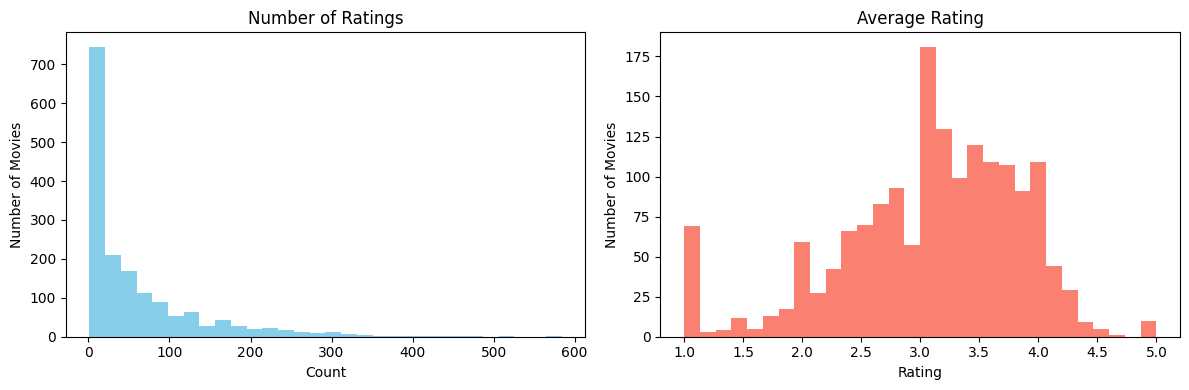

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4)) 
axes[0].hist(df_ratings["num_ratings"], bins=30, color="skyblue")
axes[0].set_title("Number of Ratings")
axes[0].set_xlabel("Count")
axes[0].set_ylabel("Number of Movies")
axes[1].hist(df_ratings["average_rating"], bins=30, color="salmon")
axes[1].set_title("Average Rating")
axes[1].set_xlabel("Rating")
axes[1].set_ylabel("Number of Movies")
plt.tight_layout()
plt.show()

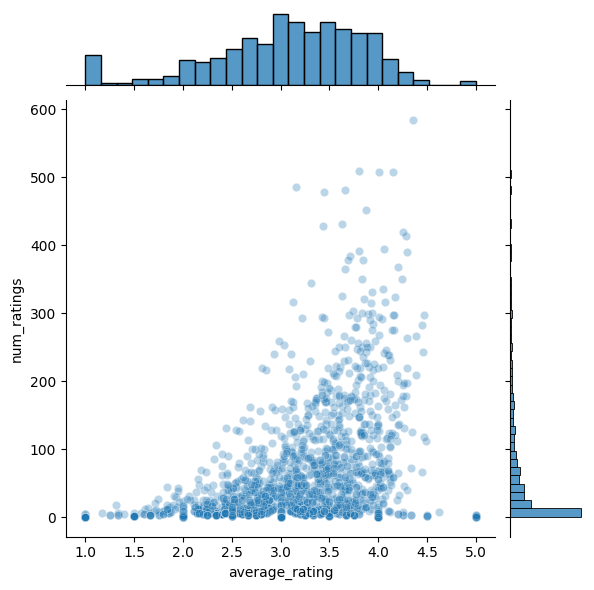

In [16]:
sns.jointplot(x="average_rating", y="num_ratings", data=df_ratings, alpha=0.3)

### Recommending Similar Movies

User-item matrix:

<img src="../../images/rec_sys.png" width="500">

შევქმნათ DataFrame ინდექსით user_id და სვეტებით title. ანუ მატრიცა, სადაც თითოეული row შეესაბამება მომხმარებელს და column - ფილმის სათაურს.
გვექნება ბევრი NaN მნიშვნელობა, რადგან უმეტეს მომხმარებელს არ აქვს ნანახი ყველა ფილმი.

In [17]:
user_movie_matrix = df_movies.pivot_table(index="user_id", columns="title", values="rating")
user_movie_matrix.head()

title,'Til There Was You (1997),1-900 (1994),101 Dalmatians (1996),12 Angry Men (1957),187 (1997),2 Days in the Valley (1996),"20,000 Leagues Under the Sea (1954)",2001: A Space Odyssey (1968),3 Ninjas: High Noon At Mega Mountain (1998),"39 Steps, The (1935)",...,Yankee Zulu (1994),Year of the Horse (1997),You So Crazy (1994),Young Frankenstein (1974),Young Guns (1988),Young Guns II (1990),"Young Poisoner's Handbook, The (1995)",Zeus and Roxanne (1997),unknown,Á köldum klaka (Cold Fever) (1994)
user_id,,,,,,,,,,,,,,,,,,,,,
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,2.0,5.0,NaN,NaN,3.0,4.0,NaN,NaN,...,NaN,NaN,NaN,5.0,3.0,NaN,NaN,NaN,4.0,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [18]:
# ყველაზე უფრო ხშირად შეფასებული ფილმები
df_ratings.sort_values("num_ratings", ascending=False).head(10)

,average_rating,num_ratings
title,,
Star Wars (1977),4.359589,584
Contact (1997),3.803536,509
Fargo (1996),4.155512,508
Return of the Jedi (1983),4.007890,507
Liar Liar (1997),3.156701,485
"English Patient, The (1996)",3.656965,481
Scream (1996),3.441423,478
Toy Story (1995),3.878319,452
Air Force One (1997),3.631090,431


შევარჩიოთ ორი ფილმი: 
* starwars, a sci-fi movie
* Liar Liar, a comedy

In [19]:
# ამ ორი ფილმის მომხმარებლების შეფასებები 
starwars_user_ratings = user_movie_matrix["Star Wars (1977)"]
liarliar_user_ratings = user_movie_matrix["Liar Liar (1997)"]

In [20]:
# გამოვიყენოთ corrwith() მეთოდი 
similar_to_starwars = user_movie_matrix.corrwith(starwars_user_ratings)
similar_to_liarliar = user_movie_matrix.corrwith(liarliar_user_ratings)

In [21]:
# most similar movies
corr_starwars = pd.DataFrame(similar_to_starwars, columns=["Correlation"])
corr_starwars.dropna(inplace=True) # removing NaN values
corr_starwars.sort_values("Correlation", ascending=False).head(10) # sort the dataframe by correlation,

,Correlation
title,
Hollow Reed (1996),1.0
Stripes (1981),1.0
Star Wars (1977),1.0
"Beans of Egypt, Maine, The (1994)",1.0
Safe Passage (1994),1.0
"Old Lady Who Walked in the Sea, The (Vieille qui marchait dans la mer, La) (1991)",1.0
"Outlaw, The (1943)",1.0
"Line King: Al Hirschfeld, The (1996)",1.0
Hurricane Streets (1998),1.0


შესაძლოა ზოგიერთი ფილმი არ იყოს აღებული ფილმის მსგავსი. ეს იმის გამოა, რომ ზოგიერთი ფილმი მხოლოდ ერთ მომხმარებელს აქვს ნანახი, რომელსაც ასევე star wars აქვს ნანახი. 

ამიტომ მხოლოდ ის ფილმები განვიხილოთ, რომლებსაც 100-ზე მეტი შეფასება აქვთ.

In [22]:
corr_starwars = corr_starwars.join(df_ratings["num_ratings"])
corr_starwars = corr_starwars[corr_starwars["num_ratings"] > 100]
corr_starwars.sort_values("Correlation", ascending=False).head()

,Correlation,num_ratings
title,,
Star Wars (1977),1.000000,584
"Empire Strikes Back, The (1980)",0.748353,368
Return of the Jedi (1983),0.672556,507
Raiders of the Lost Ark (1981),0.536117,420
Austin Powers: International Man of Mystery (1997),0.377433,130


In [23]:
# მეორე ფილმისთვის
corr_liarliar = pd.DataFrame(similar_to_liarliar, columns=["Correlation"])
corr_liarliar.dropna(inplace=True)
corr_liarliar = corr_liarliar.join(df_ratings["num_ratings"])
corr_liarliar = corr_liarliar[corr_liarliar["num_ratings"] > 100]
corr_liarliar.sort_values("Correlation", ascending=False).head()

,Correlation,num_ratings
title,,
Liar Liar (1997),1.000000,485
Batman Forever (1995),0.516968,114
"Mask, The (1994)",0.484650,129
Down Periscope (1996),0.472681,101
Con Air (1997),0.469828,137


### Content-Based Recommender
მომხმარებელს ურჩევს ისეთ ფილმებს, რომლებსაც აქვთ მსგავსი შინაარსობრივი მახასიათებლები (მაგ. ჟანრები) იმ ფილმთან, რომელიც მომხმარებელს უკვე მოსწონს.

1. ყოველი ფილმისთვის წარმოდგენილია თავისი ჟანრებით (მაგ. Action, Comedy).
2. ვითვლით მსგავსებას ჟანრებს შორის.
3. თუ მომხმარებელი უყურებს ფილმს A, ვთავაზობთ მას სხვა ფილმებს, რომლებსაც შინაარსობრივად მსგავსი ჟანრები აქვთ.

ეს არის მარტივი და სწრაფი რეკომენდაციის მეთოდი, რომელიც არ საჭიროებს მომხმარებლის ქულების ისტორიას — მხოლოდ ფილმების აღწერას.

In [69]:
columns = [
    "movie_id", "title", "release_date", "video_release_date", "IMDb_URL",
    "unknown", "Action", "Adventure", "Animation", "Children's", "Comedy", "Crime", "Documentary",
    "Drama", "Fantasy", "Film-Noir", "Horror", "Musical", "Mystery", "Romance", "Sci-Fi",
    "Thriller", "War", "Western"
]

df_genres = pd.read_csv(
    "../../datasets/movielens/u.item",
    sep="|",
    encoding="latin-1",
    names=columns,
    usecols=["title"] + columns[5:]  # skip video_release and IMDb
)
df_genres.head()

,title,unknown,Action,Adventure,Animation,Children's,Comedy,Crime,Documentary,Drama,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,Toy Story (1995),0,0,0,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0
1,GoldenEye (1995),0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
2,Four Rooms (1995),0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
3,Get Shorty (1995),0,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0
4,Copycat (1995),0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0


In [70]:
similarity = cosine_similarity(df_genres.iloc[:, 1:]) 

In [71]:
def recommend(movie_title, df, similarity_matrix, top_n=5):
    if movie_title not in df["title"].values:
        return f"Movie '{movie_title}' not found."
    
    idx = df[df["title"] == movie_title].index[0]
    sim_scores = list(enumerate(similarity_matrix[idx]))
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)[1:top_n+1]
    return df.iloc[[i[0] for i in sim_scores]]["title"].tolist()

In [72]:
recommend("Toy Story (1995)", df_genres, similarity)

['Aladdin and the King of Thieves (1996)',
 'Aladdin (1992)',
 'Goofy Movie, A (1995)',
 'Santa Clause, The (1994)',
 'Home Alone (1990)']

Cosine similarity ზომავს ორი ვექტორის მიმართულების მსგავსებას და არ აქცევს ყურადღებას მათ სიგრძეს.
ეს განსაკუთრებით გამოსადეგია მაშინ, როცა გვინდა გავარკვიოთ, რამდენად მსგავსად იქცევიან მომხმარებლები.

ორი ვექტორის A და B კოსინუსური მსგავსება გამოითვლება ასე:

$$
\text{cosine\_similarity}(A, B) = \frac{A \cdot B}{\|A\| \cdot \|B\|}
$$

სადაც:

* $A \cdot B$ — სკალარული ნამრავლია (dot product)
* $\|A\|$ და $\|B\|$ — ვექტორების ევკლიდური ნორმები (lengths)

**მაგალითი**: 

A - უყვარს ყავა, B - უყვარს ჩაი, C - უყვარს ყავაც და ჩაიც:

```
A = [1, 0]

B = [0, 1]

C = [1, 1]
```
კოსინუსური მსგავსება:

$$
\cos(\theta) = \frac{A \cdot B}{\|A\| \cdot \|B\|}
$$

სკალარული ნამრავლი: $[1,0] \cdot [0,1] = 0$

სიგრძეები (ნორმები): ${\|A\| =1,  \|B\|=1},$

შესაბამისად: $\cos(\theta) = 0$


* A და C:
  $$
  \frac{1·1 + 0·1}{\sqrt{1}\cdot\sqrt{2}} \approx 0.71
  $$

* B და C:
  $$
  \frac{0·1 + 1·1}{\sqrt{1}\cdot\sqrt{2}} \approx 0.71
  $$

Same direction → similar taste

Perpendicular → different taste

---

### Collaborative Filtering
* კოლაბორაციული ფილტრაცია ქმნის რეკომენდაციებს მომხმარებლების დამოკიდებულებების მიხედვით
* შინაარსზე დაფუძნებული რეკომენდაციის სისტემები ფოკუსირდებიან თავად ობიექტების მახასიათებლებზე და მსგავსების მიხედვით აკეთებენ რეკომენდაციებს.

---
კოლაბორაციული ფილტრაცია უფრო ხშირად გამოიყენება, ვიდრე შინაარსზე დაფუძნებული სისტემები, რადგან ის უკეთეს შედეგებს იძლევა და მარტივად გასაგებია.
ალგორითმს აქვს უნარი თავად ისწავლოს, რომელი მახასიათებლები გამოიყენოს.

კოლაბორაციული ფილტრაცია:

* მეხსიერებაზე (მატრიცაზე) დაფუძნებული ფილტრაცია
* მოდელზე დაფუძნებული ფილტრაცია (მაგ. კოსინუსური მსგავსების გამოთვლით)

#### Memory-Based Collaborative Filtering 

* მომხმარებელზე დაფუძნებული ფილტრაცია (user-item filtering)
    - „მომხმარებლებს, რომლებიც შენსავით იქცევიან, ასევე მოეწონათ …“
* ობიექტზე დაფუძნებული ფილტრაცია (item-item filtering)
    -  „მომხმარებლებს, რომლებსაც ეს ობიექტი მოეწონათ, ასევე მოეწონათ …“
 
<img src="../../images/memory_based_cf.png" width="500">

In [78]:
df_movies.head()

,user_id,item_id,rating,timestamp,title
0,0,50,5,1997-12-04 15:55:49,Star Wars (1977)
1,0,172,5,1997-12-04 15:55:49,"Empire Strikes Back, The (1980)"
2,0,133,1,1997-12-04 15:55:49,Gone with the Wind (1939)
3,196,242,3,1997-12-04 15:55:49,Kolya (1996)
4,186,302,3,1998-04-04 19:22:22,L.A. Confidential (1997)


<img src="../../images/user-item_m.png" width="400">

In [79]:
# Train / Test data
train_data, test_data = train_test_split(df_movies, test_size=0.2, random_state=42)

უნდა შევქმნათ ორი user-item მატრიცა (943 x 1682), გამოვითვალოთ similarity values. 

In [80]:
# Create two user-item matrices, one for training and another for testing
train_data_matrix = np.zeros((n_users, n_items))
for line in train_data.itertuples():
    train_data_matrix[line[1]-1, line[2]-1] = line[3]  

test_data_matrix = np.zeros((n_users, n_items))
for line in test_data.itertuples():
    test_data_matrix[line[1]-1, line[2]-1] = line[3]

მომხმარებლებს შორის მსგავსება (User-User Filtering):

→ ვეძებთ ისეთ მომხმარებლებს, რომლებსაც აქვთ მსგავსი შეფასებები.

მაგალითად: თუ მომხმარებელი A და B ორივე ანიჭებს მაღალ შეფასებებს ერთსა და იმავე ფილმებს, ისინი ერთმანეთის მსგავსი არიან.

ობიექტებს შორის მსგავსება (Item-Item Filtering):

→ ვეძებთ ისეთ ფილმებს, რომლებიც მოსწონთ ერთსა და იმავე მომხმარებლებს.

მაგალითად: თუ ბევრ მომხმარებელს მოეწონა როგორც "Inception", ისე "Interstellar", მაშინ ეს ფილმები ერთმანეთს ჰგვანან.

გამოვიყენოთ pairwise_distances ფუნქცია cosine similarity-ის გამოსათვლელად. მნიშვნელობები იქნება 0-დან 1-მდე, რადგანაც ყველა შეფასება დადებითია.

In [34]:
user_similarity = pairwise_distances(train_data_matrix, metric="cosine")
item_similarity = pairwise_distances(train_data_matrix.T, metric="cosine")

როგორ კეთდება პროგნოზი რეკომენდაციის სისტემებში?

როცა გვინდა გავიგოთ, მოეწონება თუ არა მომხმარებელს კონკრეტული ფილმი, ვიყენებთ უკვე არსებული შეფასებებისა და მსგავსებების ანალიზს. ამისთვის გვაქვს ორი ძირითადი მიდგომა:

---
მომხმარებელზე დაფუძნებული რეკომენდაცია (User-based filtering)

აქ საშუალო შეფასებას ვაკლებთ, რათა ვნახოთ შეფასების გადახრა მისი ჩვევისგან - მომხმარებლების ქცევითი განსხვავებების გამო მხოლოდ გემოვნების მსგავსებაზე ვფოკუსირდებით (როდესაც მომხმარებლების ქულების მიცემის სტილი განსხვავდება, თუმცა სინამდვილეში ორივეს გემოვნება ერთნაირია).

- ვპოულობთ მომხმარებლებს, რომლებსაც აქვთ მსგავსი გემოვნება
- ვაკვირდებით, რას უყურეს ან შეაფასეს მათ
- თუ A-ს მსგავს მომხმარებლებს რაღაც მოეწონათ, ალბათ A-საც მოეწონება

ობიექტზე დაფუძნებული რეკომენდაცია (Item-based filtering)

- ვხედავთ, რომელი ფილმები ჰგავს ერთმანეთს
- თუ A-ს მოეწონა რომელიმე ფილმი, ურჩევს მსგავს ფილმებს
- აქ სხვა მომხმარებლებს არ ვითვალისწინებთ, მხოლოდ A-ს  გემოვნებაზე ვართ ფოკუსირებული

In [35]:
def predict(ratings, similarity, type="user"):
    if type == "user":
        mean_user_rating = ratings.mean(axis=1)
        #You use np.newaxis so that mean_user_rating has same format as ratings
        ratings_diff = (ratings - mean_user_rating[:, np.newaxis]) 
        pred = mean_user_rating[:, np.newaxis] + similarity.dot(ratings_diff) / np.array([np.abs(similarity).sum(axis=1)]).T
    elif type == "item":
        pred = ratings.dot(similarity) / np.array([np.abs(similarity).sum(axis=1)])     
    return pred

In [36]:
item_prediction = predict(train_data_matrix, item_similarity, type="item")
user_prediction = predict(train_data_matrix, user_similarity, type="user")

რეკომენდაციის სისტემების ეფექტურობის შესაფასებლად ერთ-ერთი ყველაზე ხშირად გამოყენებული მეტრიკა არის RMSE - Root Mean Squared Error.

In [37]:
def rmse(prediction, ground_truth):
    prediction = prediction[ground_truth.nonzero()].flatten() 
    ground_truth = ground_truth[ground_truth.nonzero()].flatten()
    return sqrt(mean_squared_error(prediction, ground_truth))

In [38]:
print("User-based CF RMSE: " + str(rmse(user_prediction, test_data_matrix)))
print("Item-based CF RMSE: " + str(rmse(item_prediction, test_data_matrix)))

User-based CF RMSE: 3.0917949759965824
Item-based CF RMSE: 3.4400991616741443


* MovieLens dataset-ში შეფასებები მერყეობს 1-დან 5-მდე
* რაც უფრო დაბალია RMSE, მით უკეთესია მოდელი, 0 იქნება იდეალური შედეგი

---

| RMSE დიაპაზონი | შეფასება           |
| -------------- | ------------------ |
| 0.5 - 1.0      | შესანიშნავი        |
| 1.0 - 1.5      | ძალიან კარგი       |
| 1.5 - 2.0      | კარგი              |
| 2.0 - 2.5      | დამაკმაყოფილებელი  |
| 2.5 - 3.0      | სუსტი              |
| > 3.0      | დაბალი სიზუსტე |

მეხსიერებაზე დაფუძნებული ალგორითმები მარტივია და უზრუნველყოფს შედარებით მისაღებ პროგნოზების სიზუსტეს. თუმცა, ამ მიდგომას აქვს მნიშვნელოვანი მინუსები:

* დიდი მოცულობის რეალურ მონაცემებთან
* ე.წ. cold-start პრობლემა - როცა სისტემაში ჩნდება ახალი მომხმარებელი ან ახალი ობიექტი, რომელსაც ჯერ არ აქვს არცერთი შეფასება

#### Model-based Collaborative Filtering 

* ეფუძნება Matrix Factorization (MF)-ს. 
<img src="../../images/factorization.webp" width="700">

MF-ის მიზანია:

* მომხმარებლების ფარული პრეფერენცების და
* ობიექტების (მაგ. ფილმების) ფარული მახასიათებლების შესწავლა — ანუ ფაქტორების აღმოჩენა, რომლებიც განსაზღვრავენ შეფასებებს.

შემდეგ, ეს ფარული მახასიათებლები გამოიყენება იმისათვის, რომ გამოვთვალოთ არარსებული შეფასებები მომხმარებლის და ობიექტის ფარული ვექტორების სკალარული ნამრავლით (dot product).


sparsity ნიშნავს, რამდენი მონაცემი აკლია მთლიან მატრიცაში (user-item matrix).
მატრიცა ხშირად არის უზარმაზარი, მაგრამ მომხმარებელთა უმეტესობას მხოლოდ რამდენიმე ფილმი აქვს შეფასებული.

---
$$
\text{sparsity} = \frac{\text{ნულოვანი ელემენტების რაოდენობა}}{\text{ელემენტების საერთო რაოდენობა}},
$$
ანუ:
$$
\text{sparsity} = 1 - \frac{\text{შევსებული ელემენტები}}{\text{მთლიანი ზომა}},
$$

ანუ:

$$
\text{sparsity} = 1 - \frac{\text{რეიტინგების რაოდენობა}}{\text{მომხმარებლები} \times \text{ფილმები}}
$$

In [39]:
# დავთვალოთ MovieLens 100K dataset-ისთვის
n_ratings = len(df_movies)

sparsity = 1 - (n_ratings / (n_users * n_items))
print(f"The sparsity level of MovieLens100K is : {sparsity*100:.2f}%")

The sparsity level of MovieLens100K is : 93.70%


| პარამეტრი          | მნიშვნელობა                |
| ------------------ | -------------------------- |
| sparsity        | 93.7%                 |
| შევსებული მონაცემი | მხოლოდ 6.3% მატრიცისა |

ამიტომ საჭიროა Matrix Factorization, რომელიც ახდენს დაბალი განზომილების გარდაქმნას და გვაძლევს შევსებული მატრიცის უკეთეს შეფასებას.

SVD — Singular Value Decomposition

Collaborative Filtering შესაძლებელია ჩამოყალიბდეს როგორც მატრიცის `X`-ის დაახლოება შემდეგი ფორმით:

$$
X \approx U S V^T
$$

---
თუ გვაქვს მომხმარებლებისა (`m`) და ობიექტების (`n`) მატრიცა `X`, სადაც განთავსებულია შეფასებები:

* `U` — *(m x r)* მატრიცა: თითო მომხმარებლის ფარული მახასიათებლების ვექტორები
* `S` — *(r x r)* დიაგონალური მატრიცა: სინგულარული მნიშვნელობები (ძალიან მნიშვნელოვანი წონები)
* $V^T$ — *(r x n)* მატრიცა: თითო ობიექტის (მაგ. ფილმის) ფარული მახასიათებლების ვექტორები

---
1. მატრიცა X (მაგ. MovieLens-ის შეფასებები) ფაქტორიზდება სამ მატრიცად: `U`, `S`, $V^T$
2. თითო მომხმარებელი და ობიექტი აღწერილი ხდება ფარული მახასიათებლებით
3. უჯრები, რომლებიც `X`-ში ცარიელია, შეივსება ამ სამ მატრიცის ნამრავლის მეშვეობით
4. ეს მიგვიყვანს პროგნოზირებულ შეფასებებამდე

---
მატრიცა `S` შეიცავს არანაკლებ ნულოვან დიაგონალურ ელემენტებს, რომლებსაც ეწოდებათ სინგულარული მნიშვნელობები. ისინი ასახავენ, რამდენად მნიშვნელოვანია კონკრეტული განზომილება მოდელისთვის.

---

შემდეგ, პროგნოზირებული შეფასება $\hat{X}$ მიიღება ასე:

$$
\hat{X} = U S V^T
$$

---

| კომპონენტი    | შინაარსი                                      |
| ------------- | --------------------------------------------- |
| `U`           | მომხმარებლის ფარული მახასიათებლები            |
| `S`           | განზომილებების მნიშვნელობები                  |
| $V^T$         | ობიექტის (ფილმის) ფარული მახასიათებლები       |
| `U * S *` $V^T$ | პროგნოზირებული შეფასებები (შევსებული მატრიცა) |

<img src="../../images/matrix_fac.webp" width="700">

In [40]:
# get SVD components from train matrix
u, s, vt = svds(train_data_matrix, k=20)
s_diag_matrix=np.diag(s)
X_pred = np.dot(np.dot(u, s_diag_matrix), vt)
print("User-based CF RMSE: " + str(rmse(X_pred, test_data_matrix)))

User-based CF RMSE: 2.647951162201311


* SVD can couse overfitting
* SVD can be very slow and computationally expensive

<img src="../../images/recommenders.png" width="700">

* ჩვენ განვიხილეთ როგორ ავაწყოთ მარტივი Collaborative Filtering-ის მეთოდები — როგორც მეხსიერებაზე დაფუძნებული (Memory-based CF), ასევე მოდელზე დაფუძნებული (Model-based CF).

* Memory-based მოდელები ეფუძნება მომხმარებლებსა და ობიექტებს შორის მსგავსებას, სადაც ვიყენებთ cosine similarity.

* Model-based CF დაფუძნებულია მატრიცის ფაქტორიზაციაზე, სადაც ვიყენებთ SVD-ს, რათა დავშალოთ შეფასებების მატრიცა ფარულ მახასიათებლებად.

* რეკომენდაციის სისტემების აგება cold-start სიტუაციებისთვის, ანუ როდესაც ახალ მომხმარებლებზე ან ფილმებზე ცოტა მონაცემია ხელმისაწვდომი, ჯერაც სერიოზული გამოწვევაა.

#### Music Recommendation System

In [42]:
# მონაცემების ჩატვირთვა
df_music = pd.read_csv("../../datasets/music/lastfm_listening_data.csv", usecols=["Username", "Artist", "Track"])
df_music.columns = ["user_id", "artist", "track"]
df_music.head()

,user_id,artist,track
0,Babs_05,Isobel Campbell,The Circus Is Leaving Town
1,Babs_05,Isobel Campbell,Dusty Wreath
2,Babs_05,Isobel Campbell,Honey Child What Can I Do?
3,Babs_05,Isobel Campbell,It's Hard To Kill A Bad Thing
4,Babs_05,Isobel Campbell,Saturday's Gone


In [43]:
# დავითვალოთ მოსმენების რაოდენობა
df_play_counts = df_music.groupby(["user_id", "artist"]).size().reset_index(name="play_count")
df_play_counts.sort_values(by="play_count", ascending=False).head()

,user_id,artist,play_count
7261,Babs_05,Sophie,367
35092,franhale,Sophie,292
48121,massdosage,Madlib,208
15727,Knapster01,Sophie,196
10111,Knapster01,Bicep,175


In [44]:
df_play_counts.user_id.nunique()

11

In [45]:
artist_user_matrix = df_play_counts.pivot_table(index="artist", columns="user_id", values="play_count", fill_value=0)

In [46]:
# Compute item-to-item similarity
artist_similarity = cosine_similarity(artist_user_matrix)
artist_similarity_df = pd.DataFrame(artist_similarity, index=artist_user_matrix.index, columns=artist_user_matrix.index)

In [47]:
def recommend_similar_artists(artist_name, similarity_df, top_n=5):
    if artist_name not in similarity_df.columns:
        return f"{artist_name} not found in dataset."
    
    similar_artists = similarity_df[artist_name].sort_values(ascending=False)
    return similar_artists[1:top_n+1]  # exclude the artist itself

In [48]:
artist = "Taylor Swift"
print(f"If you like '{artist}', you might also enjoy:")
print(recommend_similar_artists(artist, artist_similarity_df))

If you like 'Taylor Swift', you might also enjoy:
artist
Le Tigre        0.986899
Harry Styles    0.981661
Mike Posner     0.978191
The O'Jays      0.971773
Avicii          0.971132
Name: Taylor Swift, dtype: float64


#### KNN

In [49]:
user_artist_matrix = df_play_counts.pivot_table(index="user_id", columns="artist", values="play_count", fill_value=0)

In [50]:
# Fit the kNN model
knn = NearestNeighbors(metric="cosine", algorithm="brute", n_neighbors=3)  # 2 neighbors + the user itself
knn.fit(user_artist_matrix)

,n_neighbors,3
,radius,1.0
,algorithm,'brute'
,leaf_size,30
,metric,'cosine'
,p,2
,metric_params,None
,n_jobs,None


In [51]:
target_user_id = 6  # ავარჩიოთ user_id რომლის მსგავსი მომხმარებლებიც გვინდა ვიპოვოთ
target_vector = pd.DataFrame(user_artist_matrix.iloc[target_user_id]).T

In [52]:
# მსგავსი მომხმარებლების ინდექსები
distances, indices = knn.kneighbors(target_vector)

neighbor_indices = indices[0][1:]
neighbor_distances = distances[0][1:]

neighbor_user_ids = user_artist_matrix.index[neighbor_indices]
print("Nearest users:", list(neighbor_user_ids))
print("Cosine similarity:", 1 - neighbor_distances)

Nearest users: ['lobsterclaw', 'mremond']
Cosine similarity: [0.98319055 0.9010636 ]


In [53]:
df_neighbors = user_artist_matrix.iloc[indices[0]]
mask_common = (df_neighbors > 0).all(axis=0)
df_neighbors.loc[:, mask_common]

artist,///earth///,2WEI,6th Borough Project,808 State,AJ Tracey,AXERO,Aaron Frazer,Action Bronson,Adam Horovitz,Aes Dana,...,Youngmin You,Yppah,Zoufris Maracas,alt-J,gemine,gupi,serpentwithfeet,ÄTNA,Ólafur Arnalds,王健民
user_id,,,,,,,,,,,,,,,,,,,,,
jajo,1.0,1.0,1.0,2.0,1.0,1.0,12.0,1.0,1.0,1.0,...,1.0,4.0,1.0,1.0,3.0,1.0,1.0,1.0,24.0,1.0
lobsterclaw,1.0,1.0,1.0,2.0,1.0,1.0,12.0,1.0,1.0,1.0,...,1.0,4.0,1.0,1.0,3.0,1.0,1.0,1.0,24.0,1.0
mremond,1.0,1.0,1.0,2.0,1.0,1.0,12.0,1.0,1.0,1.0,...,1.0,4.0,1.0,1.0,3.0,1.0,1.0,1.0,24.0,1.0


In [54]:
mask_neighbors = (df_neighbors > 0).any(axis=0)
df_any = df_neighbors.loc[:, mask_neighbors]
df_any.loc[:, ~mask_common]

artist,Addal,Amistades Peligrosas,Angelo De Augustine,Animal Collective,Anna Calvi,Apparat,Aterciopelados,Avantasia,Bad Bunny,Badly Drawn Boy,...,Weezer,WhoMadeWho,Yaga & Mackie,Yola,Zurdok,commonalex_,panteon rococo,sjowgren,young tender,メガゾーン EX
user_id,,,,,,,,,,,,,,,,,,,,,
jajo,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,5.0,0.0,0.0,0.0,10.0
lobsterclaw,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
mremond,3.0,1.0,1.0,1.0,1.0,1.0,3.0,11.0,10.0,1.0,...,1.0,1.0,1.0,1.0,1.0,0.0,4.0,1.0,3.0,0.0


In [55]:
# Based on similarities give weights
neighbor_matrix = user_artist_matrix.loc[neighbor_user_ids]
weights = 1 - neighbor_distances
weighted_scores = (neighbor_matrix.T @ weights) / weights.sum()

In [56]:
already_listened = user_artist_matrix.iloc[target_user_id] > 0
recommendation_scores = weighted_scores[~already_listened]

# Show top 5 recommendations
recommendation_scores.sort_values(ascending=False).head(5).index.to_list()

['My darling YOU!', 'OutKast', 'Mo Troper', 'Pentagram', 'Avantasia']